# (4) Example_MNIST_Personal_Dataset

Questo notebook serve a creare una **banca dati personale** di cifre scritte a mano, disegnandole sulla lavagna interattiva.

Ogni disegno (400x400) viene solo rimpicciolito a 28x28, senza adattarlo alle immagini MNIST (niente ritaglio né centratura), e tenuto in memoria. In questo modo le cifre restano diverse da quelle viste dalle reti con MNIST (posizione, dimensione e spessore liberi) e l'allenamento sul dataset personale insegna alle reti qualcosa di nuovo. Solo nell'ultima sezione i disegni vengono salvati su disco, nella cartella `dataset_personale` e in un unico file `dataset_personale.pt`, con la stessa struttura dei file MNIST (un tensore di immagini 28x28 e uno di etichette), ma con i disegni non adattati a MNIST, così potrà essere usato in seguito per allenare o testare le reti dei notebook precedenti.

## 1. Setup and Imports

Importiamo le librerie che ci serviranno. Le funzioni della lavagna si trovano nel file `lavagna.py`, nella stessa cartella dei notebook.

In [1]:
# Importazione delle librerie fondamentali:
# numpy e matplotlib per array e grafici, torch per salvare il dataset finale come tensori (immagini 28x28 ed etichette).
import numpy as np
import matplotlib.pyplot as plt
import torch

# Lavagna per la raccolta dei disegni, salvataggio su disco e conteggio dei campioni già salvati.
from lavagna import raccogli_cifre, salva_dataset, conta_campioni

## 2. Configurazione

Scegli la cartella del dataset e quanti campioni raccogliere per ogni cifra.

La raccolta della sezione 3 parte sempre da zero e i disegni restano in memoria: il dataset salvato in precedenza (cartella `dataset_personale` e file `dataset_personale.pt`) non viene toccato finché non si esegue la sezione 5, che lo sostituisce con quello nuovo (solo se nella sezione 3 si è premuto **Fine**). Come per l'allenamento delle reti nel notebook (1), finché non si arriva al blocco di salvataggio si tiene quello vecchio.

In [2]:
# Cartella del dataset personale (viene creata se non esiste).
# Contiene due sottocartelle: "28x28" con le immagini pronte per la rete e "originali" con i disegni 400x400.
CARTELLA_DATASET = 'dataset_personale'

# Numero di disegni da raccogliere per ogni cifra (da 0 a 9).
CAMPIONI_PER_CIFRA = 10

# Solo informativo: dataset salvato attualmente su disco (verrà sostituito nella sezione 5).
print('Dataset salvato attualmente, campioni per cifra:', conta_campioni(CARTELLA_DATASET))

Dataset salvato attualmente, campioni per cifra: [11, 10, 10, 10, 10, 10, 10, 10, 10, 10]


## 3. Raccolta dei disegni

Eseguendo la cella si apre la lavagna. In alto a sinistra è indicata la cifra da disegnare: disegnala e premi **Salva** (o Invio). Le cifre vengono chieste in ordine: la lavagna resta sulla stessa cifra finché non ne hai salvati `CAMPIONI_PER_CIFRA` disegni, poi passa alla successiva (prima tutti gli 0, poi tutti gli 1, e così via), così il dataset resta bilanciato.

- **Pulisci** (o Canc) cancella la lavagna senza salvare;
- **Annulla** elimina l'ultimo disegno raccolto, se ti sei accorto di un errore;
- cliccando su uno dei riquadri numerati si sceglie a mano la cifra da disegnare. I riquadri diventano verdi quando la cifra ha raggiunto il numero di campioni richiesto.

Sotto i contatori viene mostrato l'ultimo disegno salvato così come finisce nel dataset (ridotto a 28x28, senza adattamento MNIST). Per ottenere un dataset utile conviene variare il modo di scrivere: cifre più grandi e più piccole, inclinate, con tratti diversi (ad esempio il 7 con e senza trattino, il 9 con la coda dritta e con il ricciolo).

Quando hai finito premi **Fine**: la finestra si chiude, la cella termina e i disegni passano al notebook. Se invece chiudi la finestra con la **X**, la raccolta viene annullata: nessun disegno passa al notebook e il dataset salvato resta invariato, anche eseguendo la sezione 5. Non è obbligatorio arrivare a `CAMPIONI_PER_CIFRA` disegni per cifra, si userà quello che è stato raccolto. I disegni restano in memoria (variabili `images`, `labels`, `originali`) e su disco non viene scritto nulla: rieseguendo la cella la raccolta riparte da zero.

In [3]:
# Apertura della lavagna per la raccolta: restituisce i disegni raccolti, tenuti in memoria.
images, labels, originali = raccogli_cifre(campioni_per_cifra=CAMPIONI_PER_CIFRA)
print('Campioni per cifra:', np.bincount(labels, minlength=10))
print('Totale:', len(labels))

Campioni per cifra: [10 10 10 10 10 10 10 10 10 10]
Totale: 100


## 4. Riepilogo del dataset

Mostriamo, per ogni cifra, i primi campioni appena raccolti. È un controllo visivo utile per individuare disegni sbagliati prima di salvarli: in quel caso conviene rieseguire la sezione 3 (il dataset salvato non è ancora stato modificato).

Immagini: (100, 28, 28) - etichette: (100,)
Campioni per cifra: [10 10 10 10 10 10 10 10 10 10]


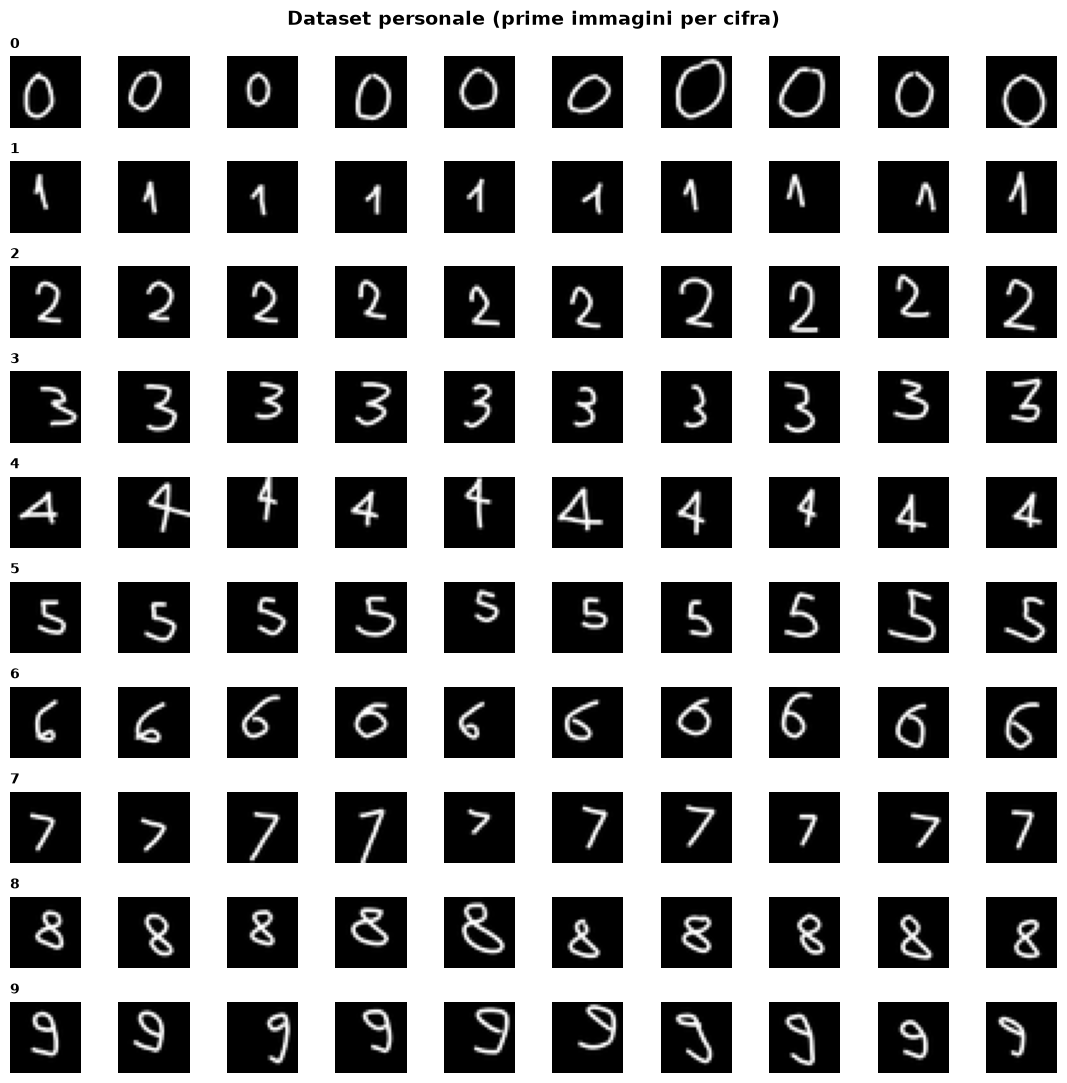

In [4]:
# Immagini e etichette raccolte nella sezione 3.
print('Immagini:', images.shape, '- etichette:', labels.shape)
print('Campioni per cifra:', np.bincount(labels, minlength=10))

# Griglia di controllo: una riga per cifra, fino a 10 campioni per riga.
n_col = 10
fig, axes = plt.subplots(10, n_col, figsize=(n_col * 1.1, 10 * 1.1))
for c in range(10):
    idx = np.where(labels == c)[0][:n_col]
    for j in range(n_col):
        ax = axes[c, j]
        ax.axis('off')
        if j < len(idx):
            ax.imshow(images[idx[j]], cmap='gray', vmin=0, vmax=255)
    axes[c, 0].set_title(str(c), loc='left', fontsize=10, fontweight='bold')
plt.suptitle('Dataset personale (prime immagini per cifra)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Salvataggio del dataset

Questo è il blocco che **sostituisce il dataset salvato** con quello appena raccolto:
- nella cartella `dataset_personale` vengono scritti i PNG (28x28 e originali), eliminando quelli precedenti;
- nel file `dataset_personale.pt` vengono salvate tutte le immagini, con la stessa struttura dei dati MNIST (stesso tipo e dimensione dei tensori; i disegni restano quelli ridotti a 28x28, non adattati a MNIST):
  - `images`: tensore `uint8` di dimensione (N, 28, 28), valori da 0 a 255;
  - `labels`: tensore `int64` di dimensione (N), la cifra disegnata.

Nel file i pixel restano quelli del disegno (da 0 a 255): la normalizzazione non viene salvata, ma applicata al momento dell'uso (sezione 5.1).

Se nella sezione 3 la lavagna è stata chiusa con la X (o non è stato raccolto nessun disegno), il dataset precedente viene lasciato com'è.

In [5]:
# Salvataggio del dataset personale: sostituisce i PNG nella cartella e il file dataset_personale.pt.
if len(labels) == 0:
    print('Lavagna chiusa con la X (o nessun disegno): il dataset salvato in precedenza resta invariato.')
else:
    salva_dataset(images, labels, originali, CARTELLA_DATASET)
    dataset_personale = {
        'images': torch.from_numpy(images),
        'labels': torch.from_numpy(labels),
    }
    torch.save(dataset_personale, 'dataset_personale.pt')
    print('Salvato dataset_personale.pt con {} immagini'.format(len(labels)))

Salvati 100 disegni nella cartella 'dataset_personale' (dataset precedente sostituito)
Salvato dataset_personale.pt con 100 immagini


### 5.1 Utilizzo del dataset (anteprima)

Per passare i disegni alle reti dei notebook precedenti, i valori dei pixel vanno preparati nello stesso formato con cui le reti sono state allenate (sezione 2 del notebook 1):
- i pixel vengono portati da 0-255 a valori tra 0 e 1;
- i valori vengono normalizzati con media 0.1307 e deviazione standard 0.3081;
- le etichette vengono convertite in formato "one-hot".

La normalizzazione **non adatta il disegno a MNIST**: posizione, dimensione e spessore della cifra restano esattamente quelli disegnati sulla lavagna. Cambia solo la scala dei valori dei pixel, cioè l'"unità di misura" dell'ingresso che le reti si aspettano: i pesi delle reti sono stati imparati su valori in questa scala, e senza normalizzazione le reti riconoscono molto peggio qualsiasi immagine, comprese quelle di MNIST. 0.1307 e 0.3081 sono quindi due costanti fisse, uguali per tutte le immagini: le usano anche la lavagna e il fine-tuning del notebook (2).

L'unico adattamento applicato ai disegni è quello delle dimensioni: il disegno 400x400 viene rimpicciolito a 28x28, perché le reti accettano solo immagini di quella dimensione.

La cella seguente legge il file salvato (quindi funziona anche senza rifare la raccolta) e crea un `DataLoader` pronto all'uso, che servirà quando alleneremo le reti anche su questi dati.

In [6]:
# Caricamento del file e preparazione dei tensori come nel DataLoader MNIST del notebook (1):
# cambiano solo i valori dei pixel, i disegni non vengono adattati a MNIST.
data = torch.load('dataset_personale.pt')
x = data['images'].float().unsqueeze(1) / 255.0             # (N, 1, 28, 28), valori 0-1 come ToTensor()
x = (x - 0.1307) / 0.3081                                    # stessa scala dei pixel usata in allenamento (non modifica il disegno)
y = torch.nn.functional.one_hot(data['labels'], 10).float()  # etichette one-hot come nel notebook (1)

personal_dataset = torch.utils.data.TensorDataset(x, y)
personal_loader = torch.utils.data.DataLoader(personal_dataset, batch_size=64, shuffle=True)

inputs, targets = next(iter(personal_loader))
print('Esempio di batch:', inputs.shape, targets.shape)

Esempio di batch: torch.Size([64, 1, 28, 28]) torch.Size([64, 10])
